In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("alunos_senai_sig.csv")


1. Monte um gráfico que mostre as maiores e menores médias de cada curso (qualquer gráfico)

                Maior média  Menor média
Curso                                   
Banco de Dados          9.6          4.6
Design                  9.9          4.5
Java                   10.0          4.2
Python                  9.4          4.0


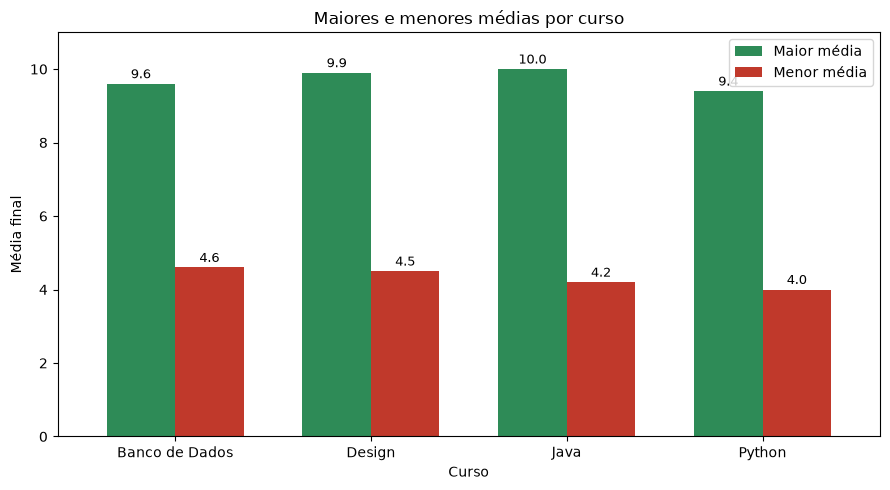

In [6]:
resumo = df.groupby('Curso')['Media_Final'].agg(['max', 'min'])
resumo.columns = ['Maior média', 'Menor média']
print(resumo)

ax = resumo.plot(kind='bar', figsize=(9, 5), color=['#2E8B57', '#C0392B'], width=0.7)
plt.title('Maiores e menores médias por curso')
plt.xlabel('Curso')
plt.ylabel('Média final')
plt.ylim(0, 11)
plt.xticks(rotation=0)
for barra in ax.patches:
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.15,
            f'{barra.get_height():.1f}', ha='center', fontsize=9)
plt.legend()
plt.tight_layout()
plt.savefig('grafico1_maior_menor_media.png', dpi=150)
plt.show()

# GRÁFICO 2 - Plot com duas linhas: notas de Design e de Java
# marcando a maior nota de cada linha com marker + texto

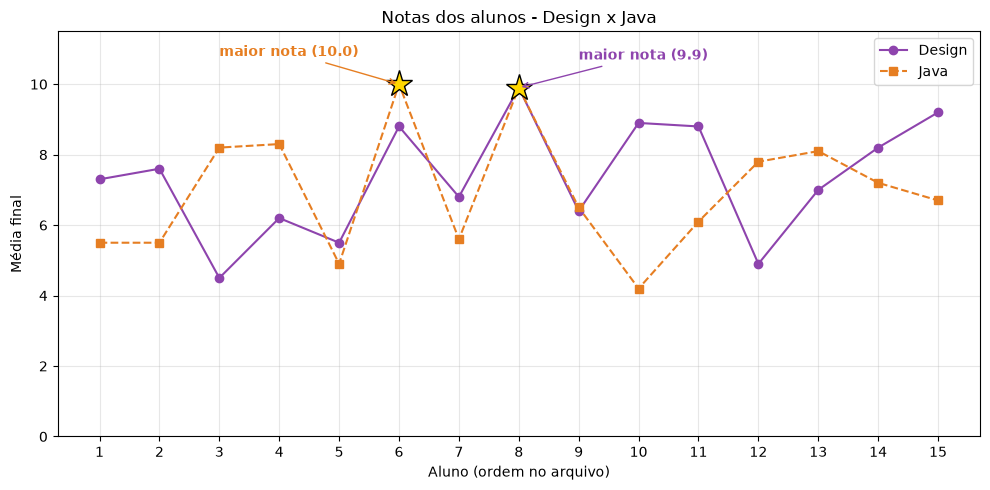

In [12]:
design = df[df['Curso'] == 'Design']['Media_Final'].reset_index(drop=True)
java = df[df['Curso'] == 'Java']['Media_Final'].reset_index(drop=True)

plt.figure(figsize=(10, 5))
plt.plot(design.index + 1, design, color='#8E44AD', marker='o', linestyle='-', label='Design')
plt.plot(java.index + 1, java, color='#E67E22', marker='s', linestyle='--', label='Java')

# Maior nota de Design
x_d = design.idxmax() + 1
y_d = design.max()
plt.plot(x_d, y_d, marker='*', markersize=20, color='gold', markeredgecolor='black')
plt.annotate(f'maior nota ({y_d})', xy=(x_d, y_d), xytext=(x_d + 1, y_d + 0.8),
             arrowprops=dict(arrowstyle='->', color='#8E44AD'), color='#8E44AD', fontweight='bold')

# Maior nota de Java
x_j = java.idxmax() + 1
y_j = java.max()
plt.plot(x_j, y_j, marker='*', markersize=20, color='gold', markeredgecolor='black')
plt.annotate(f'maior nota ({y_j})', xy=(x_j, y_j), xytext=(x_j - 3, y_j + 0.8),
             arrowprops=dict(arrowstyle='->', color='#E67E22'), color='#E67E22', fontweight='bold')

plt.title('Notas dos alunos - Design x Java')
plt.xlabel('Aluno (ordem no arquivo)')
plt.ylabel('Média final')
plt.ylim(0, 11.5)
plt.xticks(range(1, 16))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('grafico2_design_java.png', dpi=150)
plt.show()

# GRÁFICO 3 - Pizza: aprovados x reprovados em Python (média 7)


Aprovados: 5 | Reprovados: 15


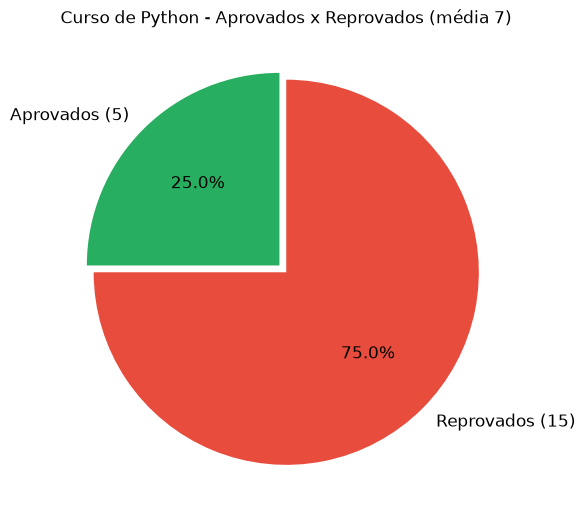

In [13]:
python = df[df['Curso'] == 'Python']
aprovados = (python['Media_Final'] >= 7).sum()
reprovados = (python['Media_Final'] < 7).sum()
print('Aprovados:', aprovados, '| Reprovados:', reprovados)

plt.figure(figsize=(6, 6))
plt.pie([aprovados, reprovados],
        labels=[f'Aprovados ({aprovados})', f'Reprovados ({reprovados})'],
        autopct='%1.1f%%', colors=['#27AE60', '#E74C3C'],
        startangle=90, explode=(0.05, 0), textprops={'fontsize': 12})
plt.title('Curso de Python - Aprovados x Reprovados (média 7)')
plt.tight_layout()
plt.savefig('grafico3_pizza_python.png', dpi=150)
plt.show()